# 05 · Weather and its effect on PV output and MPP voltage

Hourly Open-Meteo archive weather (`openmeteo2.py`) interpolated onto the 10-minute bins and onto every 1-minute snapshot (`common.interpolate_weather`: linear in time for temperature, wind, humidity, clouds; the covering hour for precipitation sums; the nearest hour for `weather_code`).

Two questions:
1. Does weather explain PV power **beyond** satellite GTI?
2. Does cell temperature / light level move the MPP voltage enough to break the single-median curtailment test?

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pvlib

from common import (
    interpolate_weather,
    load_joined,
    load_satellite,
    load_snapshots,
    load_weather,
)
from src.inverter_app.curtailment import (
    CURTAILED_VOLTAGE_RATIO,
    MPP_SAMPLE_MIN_POWER_W,
)

TZ = "Europe/Kyiv"
plt.rcParams["figure.figsize"] = (13, 4)
plt.rcParams["axes.grid"] = True


def cell_temperature(gti, temp_air, wind_kmh):
    # Faiman model: open-rack defaults; wind in m/s.
    return pvlib.temperature.faiman(gti.fillna(0), temp_air, wind_kmh / 3.6)

## Join

`clear_sky_index` = satellite GTI / satellite clear-sky GHI ratio proxy: how much the sky dims the sun at that moment.

In [2]:
weather = load_weather()
joined = load_joined()
bins = joined.join(interpolate_weather(weather, joined.index))
bins["cell_temp"] = cell_temperature(
    bins["global_tilted_irradiance"], bins["temperature_2m"],
    bins["wind_speed_10m"],
)
bins["clear_sky_index"] = (
    bins["shortwave_radiation"] / bins["shortwave_radiation_clear_sky"]
).where(bins["shortwave_radiation_clear_sky"] > 20)
data = bins[
    (bins["state"] == "unconstrained")
    & (bins["global_tilted_irradiance"] > 20)
].copy()
data["ratio"] = data["solar_power_w"] / data["global_tilted_irradiance"]
k = ((data["global_tilted_irradiance"] * data["solar_power_w"]).sum()
     / (data["global_tilted_irradiance"] ** 2).sum())
data["residual"] = data["solar_power_w"] - k * data["global_tilted_irradiance"]
print(f"{len(data)} unconstrained daylight bins, k = {k:.2f} W per W/m²")
data[["temperature_2m", "cell_temp", "wind_speed_10m",
      "relative_humidity_2m", "cloud_cover", "precipitation"]].describe(
).round(1)

407 unconstrained daylight bins, k = 3.30 W per W/m²


,temperature_2m,cell_temp,wind_speed_10m,relative_humidity_2m,cloud_cover,precipitation
count,407.0,407.0,407.0,407.0,407.0,407.0
mean,8.9,11.3,10.6,78.8,97.1,0.0
std,2.3,2.9,3.6,9.0,7.5,0.1
min,4.3,4.7,4.8,55.5,49.0,0.0
25%,7.5,9.4,7.4,72.3,98.5,0.0
50%,8.6,11.0,9.7,79.3,100.0,0.0
75%,10.6,13.2,13.2,84.6,100.0,0.0
max,14.0,21.5,19.2,97.3,100.0,0.7


## Weather over the logged period

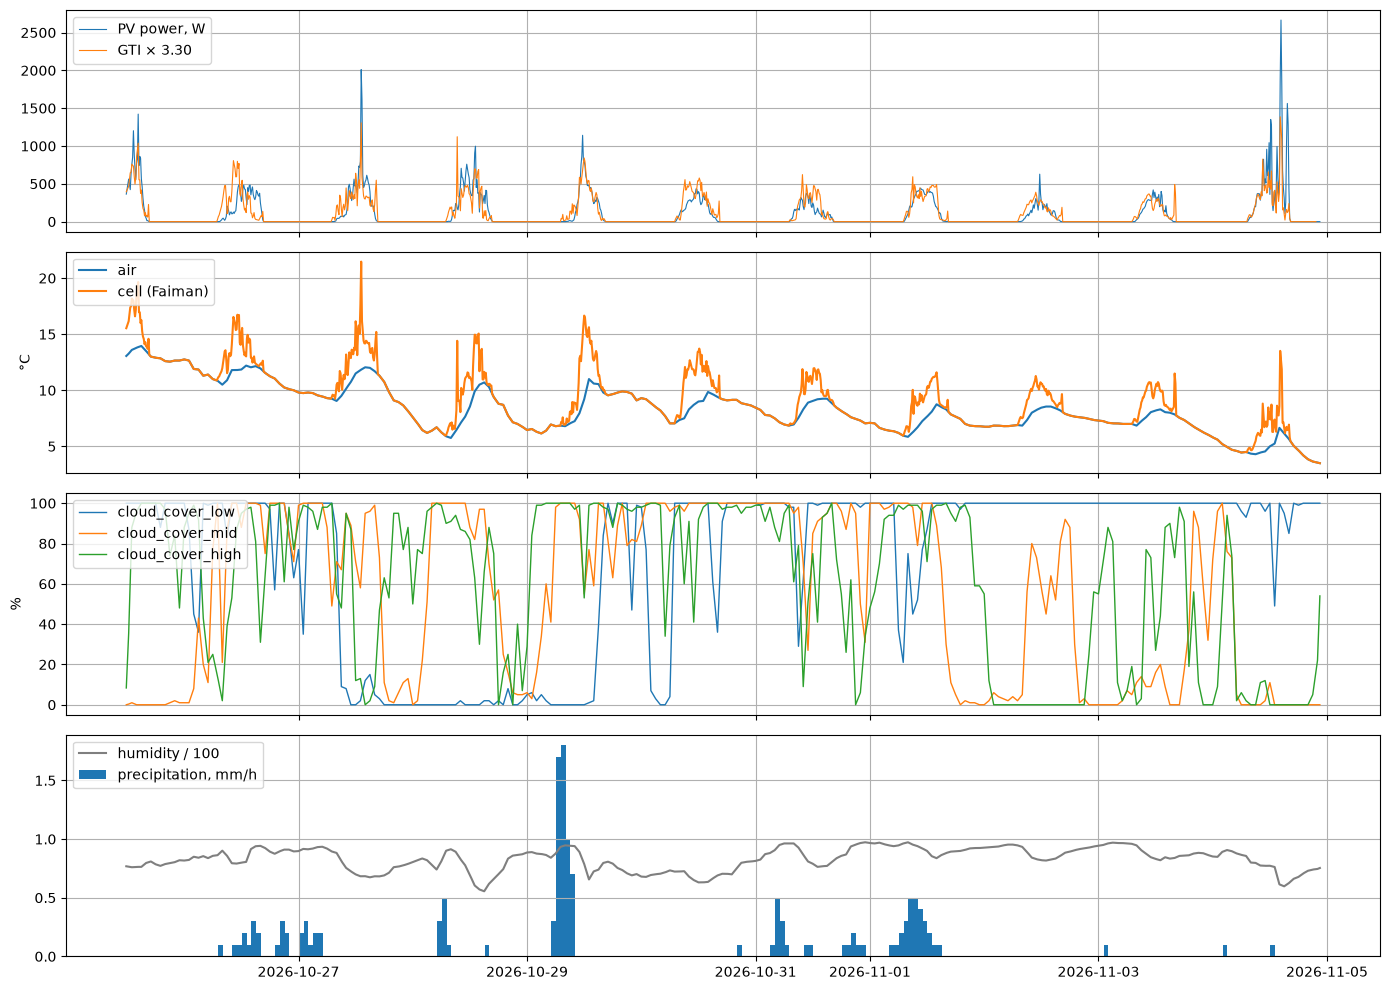

In [3]:
period = bins.tz_convert(TZ)
fig, axes = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
axes[0].plot(period["solar_power_w"], lw=0.8, label="PV power, W")
axes[0].plot(period["global_tilted_irradiance"] * k, lw=0.8,
             label=f"GTI × {k:.2f}")
axes[0].legend(loc="upper left")
axes[1].plot(period["temperature_2m"], label="air")
axes[1].plot(period["cell_temp"], label="cell (Faiman)")
axes[1].set_ylabel("°C")
axes[1].legend(loc="upper left")
for col in ["cloud_cover_low", "cloud_cover_mid", "cloud_cover_high"]:
    axes[2].plot(period[col], lw=1, label=col)
axes[2].set_ylabel("%")
axes[2].legend(loc="upper left")
axes[3].bar(period.index, period["precipitation"], width=0.007,
            color="tab:blue", label="precipitation, mm/h")
axes[3].plot(period["relative_humidity_2m"] / 100, c="tab:gray",
             label="humidity / 100")
axes[3].legend(loc="upper left")
fig.tight_layout()

## 1. Does weather explain PV beyond GTI?

`ratio` = PV / GTI (array efficiency at that moment), `residual` = PV − k·GTI. If a weather variable matters it should correlate with them; GTI itself is already accounted for.

In [4]:
weather_cols = [
    "cell_temp", "temperature_2m", "wind_speed_10m", "relative_humidity_2m",
    "dew_point_2m", "cloud_cover", "cloud_cover_low", "cloud_cover_mid",
    "cloud_cover_high", "precipitation", "clear_sky_index",
]
pd.DataFrame({
    "ratio pearson": data[weather_cols].corrwith(data["ratio"]),
    "ratio spearman": data[weather_cols].corrwith(data["ratio"],
                                                  method="spearman"),
    "residual pearson": data[weather_cols].corrwith(data["residual"]),
}).round(3).sort_values("ratio spearman")

,ratio pearson,ratio spearman,residual pearson
clear_sky_index,-0.137,-0.285,-0.101
cloud_cover,-0.157,-0.213,-0.229
cloud_cover_low,-0.052,-0.185,-0.132
cloud_cover_mid,-0.192,-0.183,-0.298
relative_humidity_2m,-0.163,-0.134,-0.209
cell_temp,-0.123,-0.051,-0.079
precipitation,0.003,-0.029,-0.049
cloud_cover_high,-0.097,-0.015,-0.178
dew_point_2m,-0.146,-0.005,-0.186
temperature_2m,-0.032,0.032,-0.041


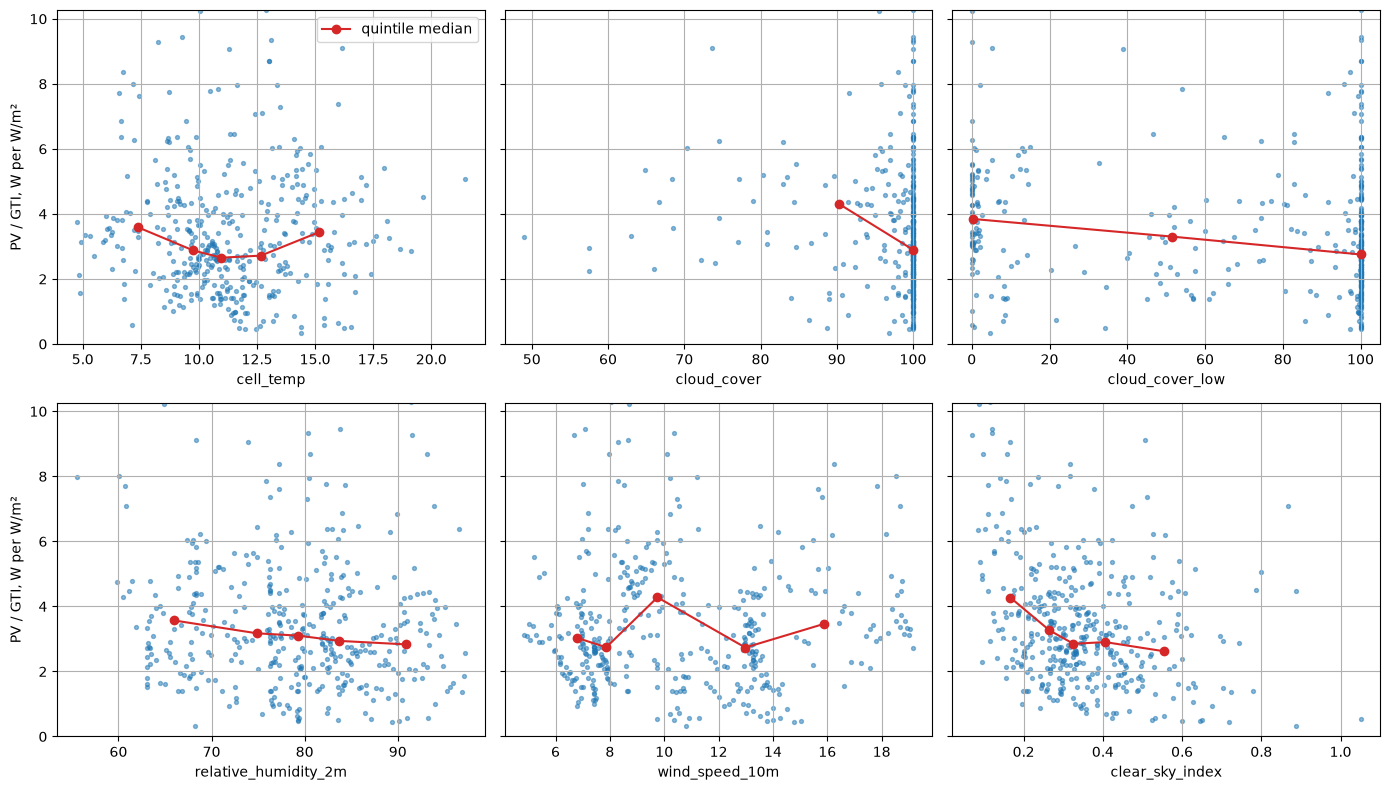

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharey=True)
for ax, col in zip(axes.flat, ["cell_temp", "cloud_cover", "cloud_cover_low",
                               "relative_humidity_2m", "wind_speed_10m",
                               "clear_sky_index"]):
    ax.scatter(data[col], data["ratio"], s=8, alpha=0.5)
    ax.set_xlabel(col)
    medians = data.groupby(pd.qcut(data[col], 5, duplicates="drop"),
                           observed=True)[["ratio", col]].median()
    ax.plot(medians[col], medians["ratio"], c="tab:red", marker="o",
            label="quintile median")
for ax in axes[:, 0]:
    ax.set_ylabel("PV / GTI, W per W/m²")
axes[0, 0].legend()
ax.set_ylim(0, data["ratio"].quantile(0.98))
fig.tight_layout()

### Model comparison with leave-one-day-out validation

Each model is fitted on all days but one and scored on the held-out day, so extra columns only win if they generalise. Weather terms enter multiplied by GTI (they scale efficiency, they don't create power).

In [6]:
def design(df, extra):
    g = df["global_tilted_irradiance"].values
    columns = [g] + [g * df[c].fillna(df[c].median()).values for c in extra]
    return np.column_stack(columns)


models = {
    "GTI": [],
    "+ cell temp": ["cell_temp"],
    "+ cloud cover": ["cloud_cover"],
    "+ low cloud": ["cloud_cover_low"],
    "+ humidity": ["relative_humidity_2m"],
    "+ clear-sky index": ["clear_sky_index"],
    "+ cell temp + low cloud + humidity": [
        "cell_temp", "cloud_cover_low", "relative_humidity_2m"],
}
day = data.index.tz_convert(TZ).date
y = data["solar_power_w"].values
rows = []
for name, extra in models.items():
    X = design(data, extra)
    predicted = np.empty_like(y, dtype=float)
    for d in sorted(set(day)):
        test = day == d
        coef, *_ = np.linalg.lstsq(X[~test], y[~test], rcond=None)
        predicted[test] = X[test] @ coef
    full, *_ = np.linalg.lstsq(X, y, rcond=None)
    rows.append({
        "model": name,
        "CV R²": 1 - ((y - predicted) ** 2).sum()
        / ((y - y.mean()) ** 2).sum(),
        "CV MAE, W": np.abs(y - predicted).mean(),
        "coefficients": np.round(full, 4).tolist(),
    })
pd.DataFrame(rows).set_index("model").round(3)

,CV R²,"CV MAE, W",coefficients
model,,,
GTI,0.328,156.184,[3.2967]
+ cell temp,0.254,164.857,"[3.3399, -0.0033]"
+ cloud cover,0.367,152.896,"[8.0354, -0.0497]"
+ low cloud,0.303,156.854,"[3.6918, -0.006]"
+ humidity,0.344,159.319,"[8.4664, -0.0677]"
+ clear-sky index,0.272,159.517,"[3.2101, 0.1759]"
+ cell temp + low cloud + humidity,0.171,178.103,"[10.3138, -0.0721, -0.0061, -0.0742]"


## 2. MPP voltage vs light and cell temperature

Readings with battery headroom and ≥ `MPP_SAMPLE_MIN_POWER_W` on pv1 — the same samples `estimate_mpp_voltages` takes its median from, so the MPPT is at the true maximum power point. GTI (instantaneous) and weather are interpolated to each 1-minute reading.

In [7]:
snapshots = load_snapshots()
gti = load_satellite()["global_tilted_irradiance_instant"].dropna()
seconds = snapshots.index.astype("int64") / 1e9
snapshots["gti"] = np.interp(seconds, gti.index.astype("int64") / 1e9,
                             gti.values, left=np.nan, right=np.nan)
snapshots = snapshots.join(interpolate_weather(weather, snapshots.index))
snapshots["cell_temp"] = cell_temperature(
    snapshots["gti"], snapshots["temperature_2m"],
    snapshots["wind_speed_10m"],
)
mpp = snapshots[
    snapshots["headroom"]
    & (snapshots["pv1_power_w"] >= MPP_SAMPLE_MIN_POWER_W)
    & (snapshots["gti"] > 10)
].copy()
median_v = mpp["pv1_voltage_v"].median()
print(f"{len(mpp)} MPP samples, median pv1 voltage {median_v:.1f} V, "
      f"cell temp {mpp['cell_temp'].min():.1f}…"
      f"{mpp['cell_temp'].max():.1f} °C")

1148 MPP samples, median pv1 voltage 324.4 V, cell temp 5.2…17.4 °C


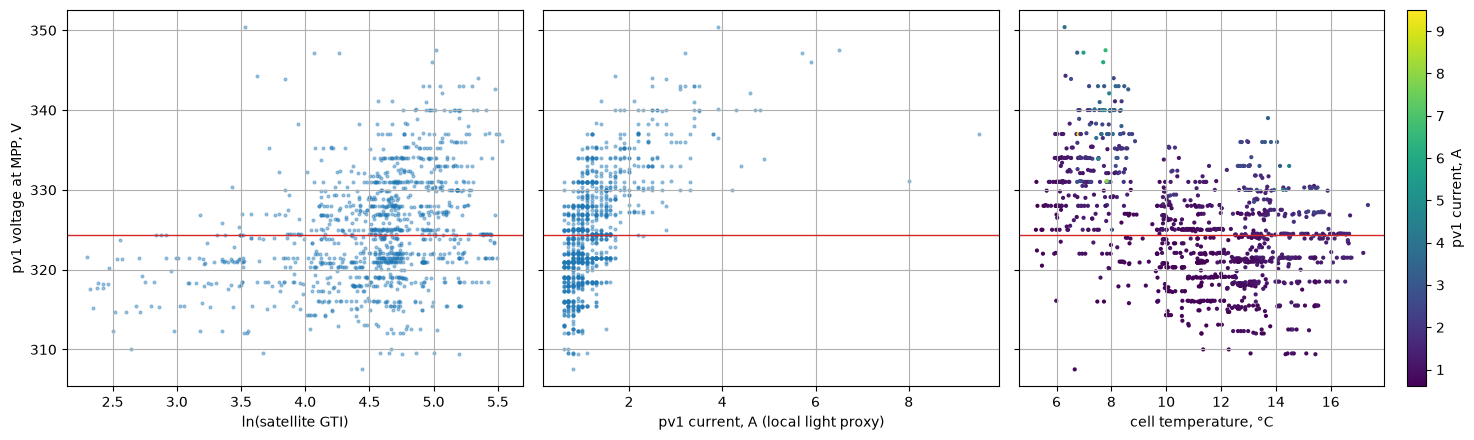

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
axes[0].scatter(np.log(mpp["gti"]), mpp["pv1_voltage_v"], s=4, alpha=0.4)
axes[0].set_xlabel("ln(satellite GTI)")
axes[1].scatter(mpp["pv1_current_a"], mpp["pv1_voltage_v"], s=4, alpha=0.4)
axes[1].set_xlabel("pv1 current, A (local light proxy)")
sc = axes[2].scatter(mpp["cell_temp"], mpp["pv1_voltage_v"], s=4,
                     c=mpp["pv1_current_a"], cmap="viridis")
fig.colorbar(sc, ax=axes[2], label="pv1 current, A")
axes[2].set_xlabel("cell temperature, °C")
for ax in axes:
    ax.axhline(median_v, c="tab:red", lw=1)
axes[0].set_ylabel("pv1 voltage at MPP, V")
fig.tight_layout()

### Fit `Vmp = a + b·ln(GTI) + c·T_cell`

Silicon datasheets give c ≈ −0.3…−0.4 %/°C of Vmp. Compare the fitted c with that: a narrow autumn temperature range may not pin it down.

In [9]:
X = np.column_stack([np.ones(len(mpp)), np.log(mpp["gti"]),
                     mpp["cell_temp"]])
coef, *_ = np.linalg.lstsq(X, mpp["pv1_voltage_v"].values, rcond=None)
mpp["expected_v"] = X @ coef
a, b, c = coef
print(f"Vmp = {a:.1f} + {b:.2f}·ln(GTI) + {c:.3f}·T_cell")
print(f"temperature coefficient: {c / median_v * 100:.3f} %/°C of Vmp")
spread = pd.DataFrame({
    "single median": mpp["pv1_voltage_v"] / median_v,
    "fitted model": mpp["pv1_voltage_v"] / mpp["expected_v"],
})
print("\nvoltage / reference on true-MPP samples (should sit at 1.0):")
spread.describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).round(3)

Vmp = 318.0 + 4.39·ln(GTI) + -1.161·T_cell
temperature coefficient: -0.358 %/°C of Vmp

voltage / reference on true-MPP samples (should sit at 1.0):


,single median,fitted model
count,1148.000,1148.000
mean,1.002,1.000
std,0.021,0.017
min,0.948,0.933
1%,0.962,0.963
5%,0.972,0.973
50%,1.000,1.000
95%,1.039,1.026
99%,1.057,1.036
max,1.080,1.074


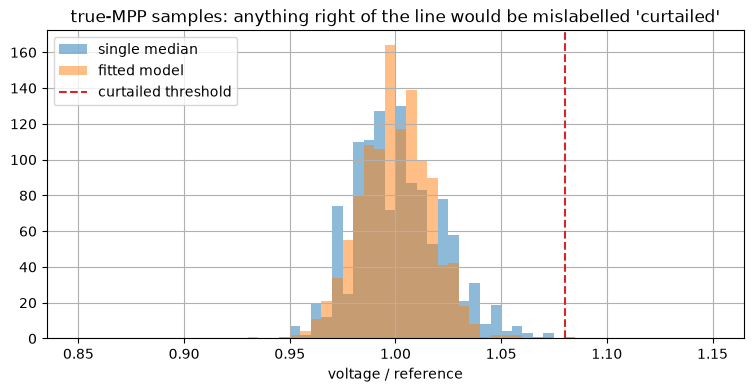

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
bins_ratio = np.linspace(0.85, 1.15, 61)
for col in spread:
    ax.hist(spread[col], bins=bins_ratio, alpha=0.5, label=col)
ax.axvline(CURTAILED_VOLTAGE_RATIO, c="tab:red", ls="--",
           label="curtailed threshold")
ax.set_xlabel("voltage / reference")
ax.set_title("true-MPP samples: anything right of the line would be "
             "mislabelled 'curtailed'")
ax.legend()

### Would the curtailment labels change?

Re-run the voltage test on readings **without** battery headroom (the only ones it decides) using the fitted expected Vmp instead of the median.

In [11]:
test = snapshots[
    ~snapshots["headroom"]
    & (snapshots["state"] != "dark")
    & (snapshots["pv1_power_w"] > 0)
    & (snapshots["gti"] > 10)
].copy()
expected = (a + b * np.log(test["gti"]) + c * test["cell_temp"])
test["by_median"] = np.where(
    test["pv1_voltage_v"] / median_v > CURTAILED_VOLTAGE_RATIO,
    "curtailed", "unconstrained")
test["by_model"] = np.where(
    test["pv1_voltage_v"] / expected > CURTAILED_VOLTAGE_RATIO,
    "curtailed", "unconstrained")
pd.crosstab(test["by_median"], test["by_model"], margins=True)

by_model,curtailed,unconstrained,All
by_median,,,
curtailed,98,3,101
unconstrained,3,2402,2405
All,101,2405,2506


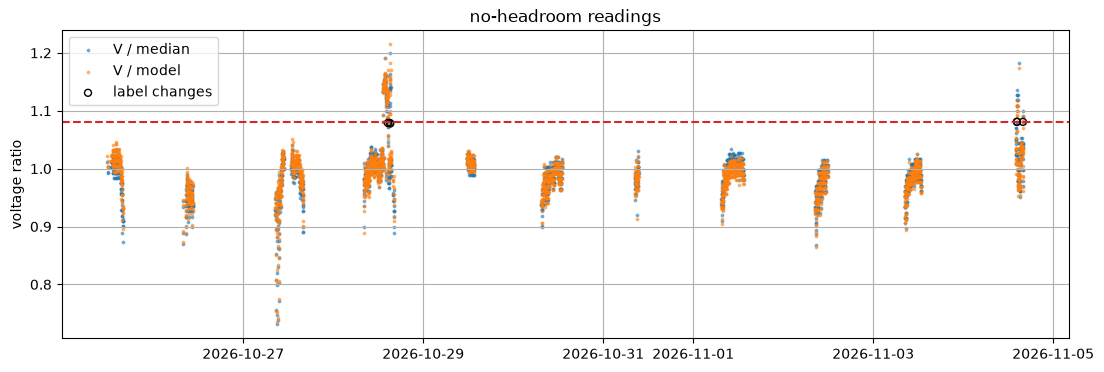

In [12]:
changed = test[test["by_median"] != test["by_model"]]
fig, ax = plt.subplots(figsize=(13, 4))
local = test.tz_convert(TZ)
ax.scatter(local.index, local["pv1_voltage_v"] / median_v, s=3,
           label="V / median", alpha=0.5)
ax.scatter(local.index, local["pv1_voltage_v"]
           / expected.loc[test.index].values, s=3,
           label="V / model", alpha=0.5)
ax.scatter(changed.tz_convert(TZ).index,
           changed["pv1_voltage_v"] / median_v, s=25, facecolors="none",
           edgecolors="k", label="label changes")
ax.axhline(CURTAILED_VOLTAGE_RATIO, c="tab:red", ls="--")
ax.set_ylabel("voltage ratio")
ax.set_title("no-headroom readings")
ax.legend(loc="upper left")